# Netflix Content Intelligence — Exploratory Analysis and Clustering

## Project Overview

This project analyses the Netflix Movies and TV Shows dataset using exploratory data analysis (EDA), statistical hypothesis testing, and unsupervised machine learning. Genre information and textual descriptions are transformed into numerical features and used to cluster similar titles. Two clustering algorithms, MiniBatch K-Means and Agglomerative Clustering, are compared using internal metrics and cluster-content inspection.

**Repository:** https://github.com/Brian-Fernandes/Netflix_EDA

### Problem Statement

The Netflix catalogue contains movies and TV shows with different genres, release years, ratings, countries, and textual descriptions. Analysing this information can help reveal patterns in the catalogue and similarities between titles. The study aims to identify important catalogue patterns, group similar titles using their genres and descriptions, and compare clustering algorithms to determine which produces the most interpretable groups.

The project focuses on content analysis and clustering rather than personalised recommendations or individual user behaviour prediction, as the available dataset does not contain user-level interaction data.

### Research Questions

1. What are the major characteristics and patterns in the Netflix catalogue?
2. Do movies and TV shows differ in their release-year distributions?
3. Is there a statistically significant association between content type and rating?
4. Can Netflix titles be grouped into meaningful clusters using genres and descriptions?
5. Which clustering algorithm provides the better balance of cluster quality and interpretability?

## Workflow, Principles and Contents

**Workflow**
1. Load, inspect, and clean the dataset
2. Perform univariate, bivariate, and multivariate EDA
3. Test selected statistical hypotheses
4. Engineer genre and description features
5. Train MiniBatch K-Means and Agglomerative Clustering (the latter on a Truncated SVD reduction)
6. Compare the models on a shared evaluation sample and interpret the clusters

**Analytical principles**
- Use the full dataset for descriptive calculations unless a step explicitly uses a sample for computational reasons.
- Use a reproducible sample for expensive metric calculations.
- Genre labels are multi-label: one title may contribute to several category counts.
- Cluster labels are arbitrary identifiers, not rankings.
- Association and cluster patterns do not establish causation.
- Clustering metrics are only comparable when their feature representation, distance metric, and evaluation sample are aligned.

**Contents**
1. [Import Libraries and Load Dataset](#1.-Import-Libraries-and-Load-Dataset)
2. [Dataset Inspection and Cleaning](#2.-Dataset-Inspection-and-Cleaning)
3. [Univariate EDA](#3.-Univariate-Exploratory-Data-Analysis)
4. [Bivariate EDA](#4.-Bivariate-Exploratory-Data-Analysis)
5. [Statistical Hypothesis Testing](#5.-Statistical-Hypothesis-Testing)
6. [Multivariate EDA](#6.-Multivariate-Exploratory-Analysis)
7. [Feature Engineering](#7.-Feature-Engineering-and-Representation)
8. [Modelling Setup](#8.-Modelling-Setup)
9. [Model 1 — MiniBatch K-Means](#9.-Model-1-—-MiniBatch-K-Means)
10. [Model 2 — Agglomerative Clustering](#10.-Model-2-—-Agglomerative-Clustering)
11. [Final Model Comparison](#11.-Final-Model-Comparison)
12. [Conclusion](#12.-Conclusion)

# 1. Import Libraries and Load Dataset

In [68]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 140)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")

# Expected dataset name from the project
candidate_files = [
    "NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv",
    "netflix_titles.csv"
]

file_path = next((f for f in candidate_files if os.path.exists(f)), None)

if file_path is None:
    raise FileNotFoundError(
        "Dataset CSV not found. Upload 'NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv' "
        "to the Colab working directory and run this cell again."
    )

df = pd.read_csv(file_path)

print(f"Dataset loaded successfully: {file_path}")
print("Dataset shape:", df.shape)
display(df.head())

Libraries imported successfully.
Dataset loaded successfully: NETFLIX MOVIES AND TV SHOWS CLUSTERING.csv
Dataset shape: (7787, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, Rodolfo Valente, Vaneza Oliveira, Rafael Lozano, Viviane Porto, Mel Fro...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi & Fantasy","In a future where the elite inhabit an island paradise far from the crowded slums, you get one chance to join the 3%..."
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, Azalia Ortiz, Octavio Michel, Carmen Beato",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies","After a devastating earthquake hits Mexico City, trapped survivors from all walks of life wait to be rescued while t..."
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence Koh, Tommy Kuan, Josh Lai, Mark Lee, Susan Leong, Benjamin Lim",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow soldiers are forced to confront a terrifying secret that's haunting t..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly, Christopher Plummer, Crispin Glover, Martin Landau, Fred Tatasciore,...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi & Fantasy","In a postapocalyptic world, rag-doll robots hide in fear from dangerous machines out to exterminate them, until a br..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aaron Yoo, Liza Lapira, Jacob Pitts, Laurence Fishburne, Jack McGee, Josh...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-counting experts with the intent of swindling millions out of Las Vegas ca...


# 2. Dataset Inspection and Cleaning

## 2.1 Initial Inspection

In [69]:
print("Column names:")
display(pd.DataFrame({"Column": df.columns}))

print("\nData types and non-null counts:")
df.info()

print("Descriptive statistics:")
display(df.describe(include="all").T)

print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
}).sort_values("Missing Count", ascending=False)

display(missing_summary)

Column names:


,Column
0,show_id
1,type
2,title
3,director
4,cast
5,country
6,date_added
7,release_year
8,rating
9,duration



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   object
 10  listed_in     7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(1), object(11)
memory usage: 730.2+ KB
Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,7787,7787,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,7787,2,Movie,5377,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,7787,7787,3%,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,5398,4049,"Raúl Campos, Jan Suter",18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7069,6831,David Attenborough,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7280,681,United States,2555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,7777,1565,"January 1, 2020",118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,7787.0,NaN,NaN,NaN,2013.93258,8.757395,1925.0,2013.0,2017.0,2018.0,2021.0
rating,7780,14,TV-MA,2863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,7787,216,1 Season,1608,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 0

Missing values:


,Missing Count,Missing Percentage
director,2389,30.68
cast,718,9.22
country,507,6.51
date_added,10,0.13
rating,7,0.09
title,0,0.00
show_id,0,0.00
type,0,0.00
release_year,0,0.00
duration,0,0.00


## 2.2 Data Cleaning

The dataset contains missing values mainly in `director`, `cast`, `country`, `date_added`, and `rating`.

- `director`, `cast`, `country`, and `date_added` missing values are represented as `"Unknown"`.
- Missing `rating` values are preserved rather than replaced with the most frequent rating.
- `date_added` is intentionally retained as text at this stage; it is converted during feature engineering.

In [70]:
# Handle missing values

df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["date_added"] = df["date_added"].fillna("Unknown")

# Preserve missing ratings instead of assigning the most frequent rating
df["rating"] = df["rating"].fillna("Unknown")

print("Missing values after cleaning:")
display(df.isna().sum().to_frame("Missing Count"))

# Verify duplicates after cleaning
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Final dataset shape:", df.shape)

Missing values after cleaning:


,Missing Count
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


Duplicate rows after cleaning: 0
Final dataset shape: (7787, 12)


# 3. Univariate Exploratory Data Analysis

Univariate analysis examines each important variable independently to understand the structure of the dataset before studying relationships between variables.

## 3.1 Content Type Distribution

,Count,Percentage
type,,
Movie,5377,69.05
TV Show,2410,30.95


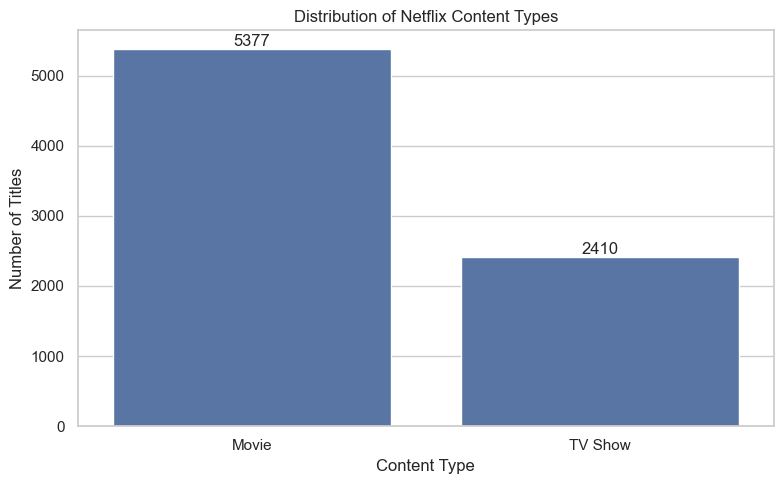

In [71]:
type_counts = df["type"].value_counts()
type_percentage = df["type"].value_counts(normalize=True).mul(100).round(2)

type_summary = pd.DataFrame({
    "Count": type_counts,
    "Percentage": type_percentage
})

display(type_summary)

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="type", order=type_counts.index)

plt.title("Distribution of Netflix Content Types")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

## 3.2 Release Year Distribution

Release year statistics:


,Release Year
count,7787.000000
mean,2013.932580
std,8.757395
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2018.000000
max,2021.000000


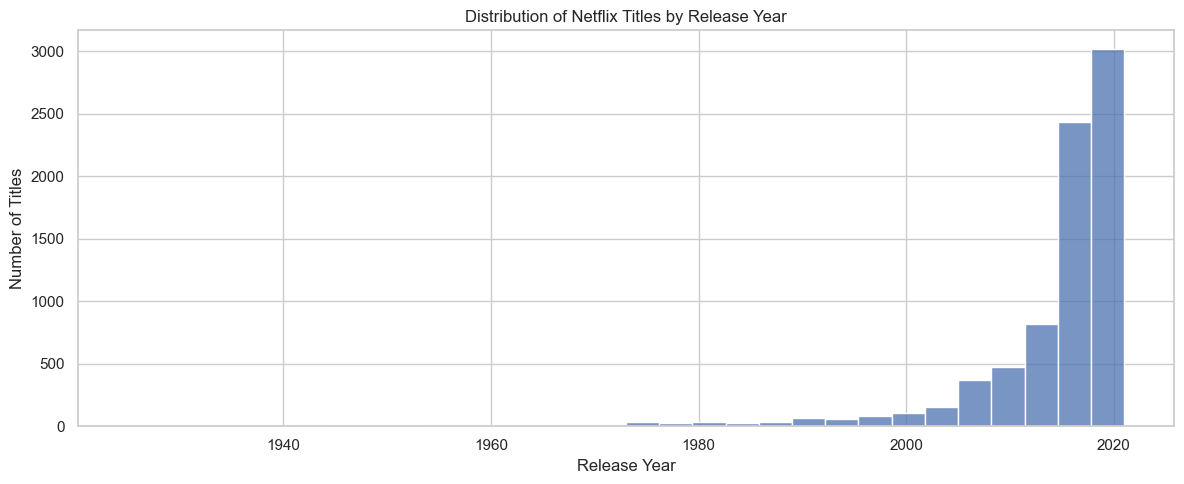

In [72]:
print("Release year statistics:")
display(df["release_year"].describe().to_frame("Release Year"))

plt.figure(figsize=(12, 5))
sns.histplot(data=df, x="release_year", bins=30)

plt.title("Distribution of Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

## 3.3 Genre / Category Distribution

`listed_in` contains multiple comma-separated categories for many titles. The values are therefore split and exploded so that each category can be counted independently.

The calculation uses **all categories**. The Top-15 chart is only a readability-focused visualization.

Number of unique genres/categories: 42


,Title Count
listed_in,
International Movies,2437
Dramas,2106
Comedies,1471
International TV Shows,1199
Documentaries,786
Action & Adventure,721
TV Dramas,704
Independent Movies,673
Children & Family Movies,532


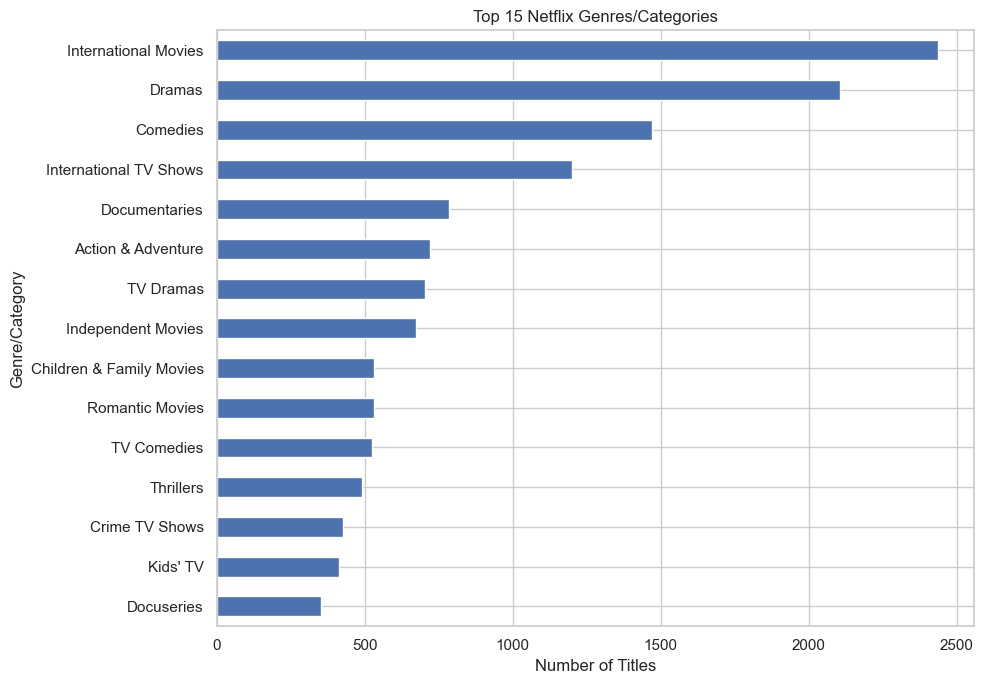

In [73]:
genre_counts = (
    df["listed_in"]
      .str.split(", ")
      .explode()
      .value_counts()
)

print("Number of unique genres/categories:", len(genre_counts))
display(genre_counts.to_frame("Title Count"))

top_genres = genre_counts.head(15).sort_values()

plt.figure(figsize=(10, 7))
ax = top_genres.plot(kind="barh")

plt.title("Top 15 Netflix Genres/Categories")
plt.xlabel("Number of Titles")
plt.ylabel("Genre/Category")
plt.tight_layout()
plt.show()

## 3.4 Country Distribution

A title can contain multiple countries, so `country` is also split and exploded.

All countries are retained for calculation. The Top-15 visualization is used only to make the distribution readable.

Number of countries represented: 121


,Title Count
country,
United States,3296
India,990
United Kingdom,722
Canada,412
France,349
...,...
Panama,1
"United Kingdom,",1
Uganda,1


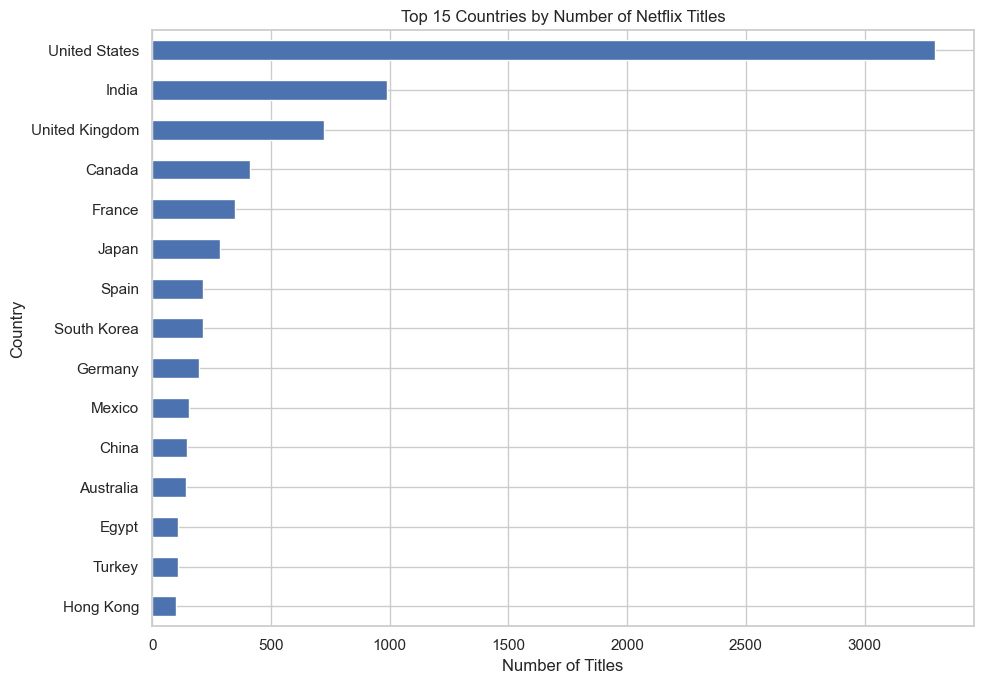

In [74]:
country_counts = (
    df["country"]
      .str.split(", ")
      .explode()
      .value_counts()
)

country_counts = country_counts[country_counts.index != "Unknown"]

print("Number of countries represented:", len(country_counts))
display(country_counts.to_frame("Title Count"))

top_countries = country_counts.head(15).sort_values()

plt.figure(figsize=(10, 7))
top_countries.plot(kind="barh")

plt.title("Top 15 Countries by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 3.5 Content Rating Distribution

Number of unique ratings: 15


,Title Count
rating,
TV-MA,2863
TV-14,1931
TV-PG,806
R,665
PG-13,386
TV-Y,280
TV-Y7,271
PG,247
TV-G,194


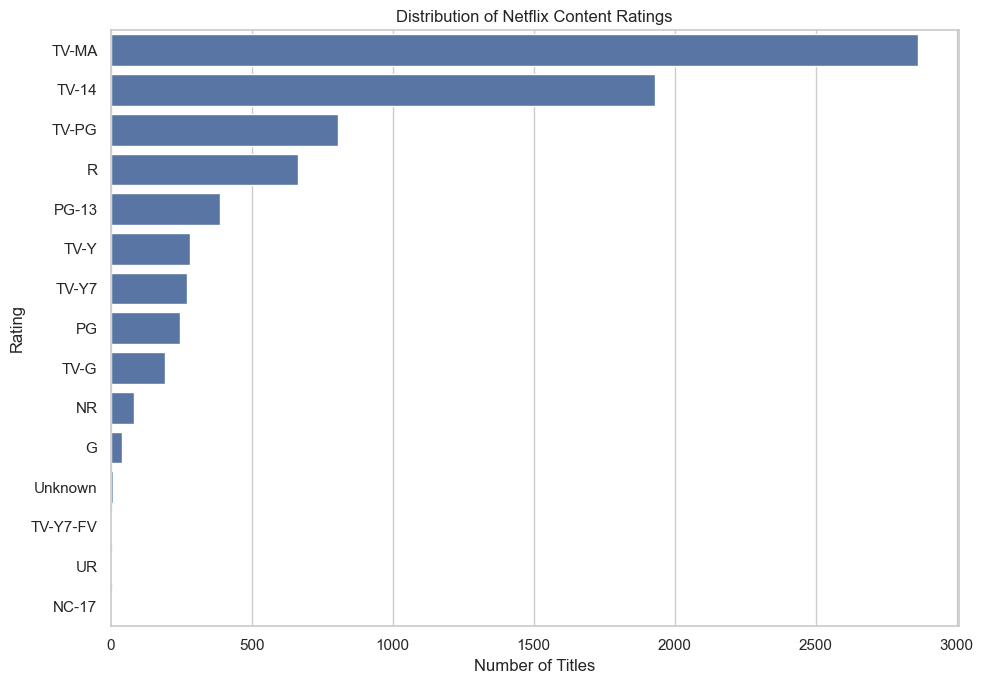

In [75]:
rating_counts = df["rating"].value_counts()

print("Number of unique ratings:", len(rating_counts))
display(rating_counts.to_frame("Title Count"))

plt.figure(figsize=(10, 7))
sns.countplot(
    data=df,
    y="rating",
    order=rating_counts.index
)

plt.title("Distribution of Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

# 4. Bivariate Exploratory Data Analysis

Bivariate analysis examines meaningful relationships between two variables. Relationships that are redundant (for example, genre labels that already encode content type) or dominated by very small samples are intentionally excluded.

## 4.1 Content Type × Rating

Content Type by Rating — Row Percentages


type,Movie,TV Show
rating,,
G,100.00,0.00
NC-17,100.00,0.00
NR,94.05,5.95
PG,100.00,0.00
PG-13,100.00,0.00
R,99.70,0.30
TV-14,65.87,34.13
TV-G,57.22,42.78
TV-MA,64.44,35.56


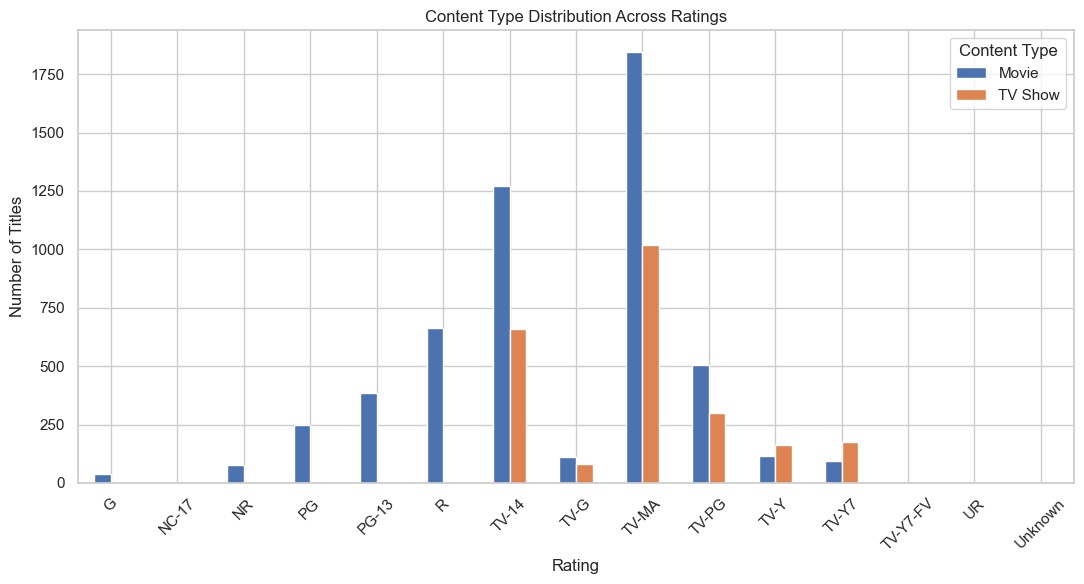

In [76]:
type_rating_counts = pd.crosstab(df["rating"], df["type"])

type_rating_pct = pd.crosstab(
    df["rating"],
    df["type"],
    normalize="index"
).mul(100).round(2)

print("Content Type by Rating — Row Percentages")
display(type_rating_pct)

type_rating_counts.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Content Type Distribution Across Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

## 4.2 Release Decade × Content Type

type,Movie,TV Show
release_decade,,
1920,0,1
1940,13,1
1950,11,0
1960,22,3
1970,63,4
1980,99,7
1990,194,31
2000,601,127
2010,3951,1760


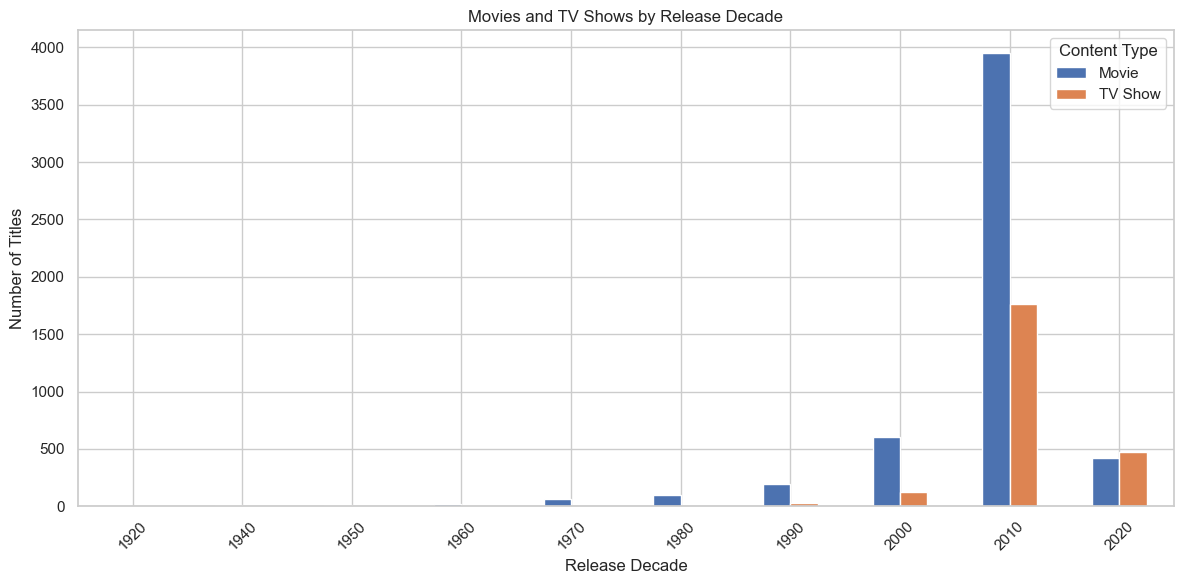

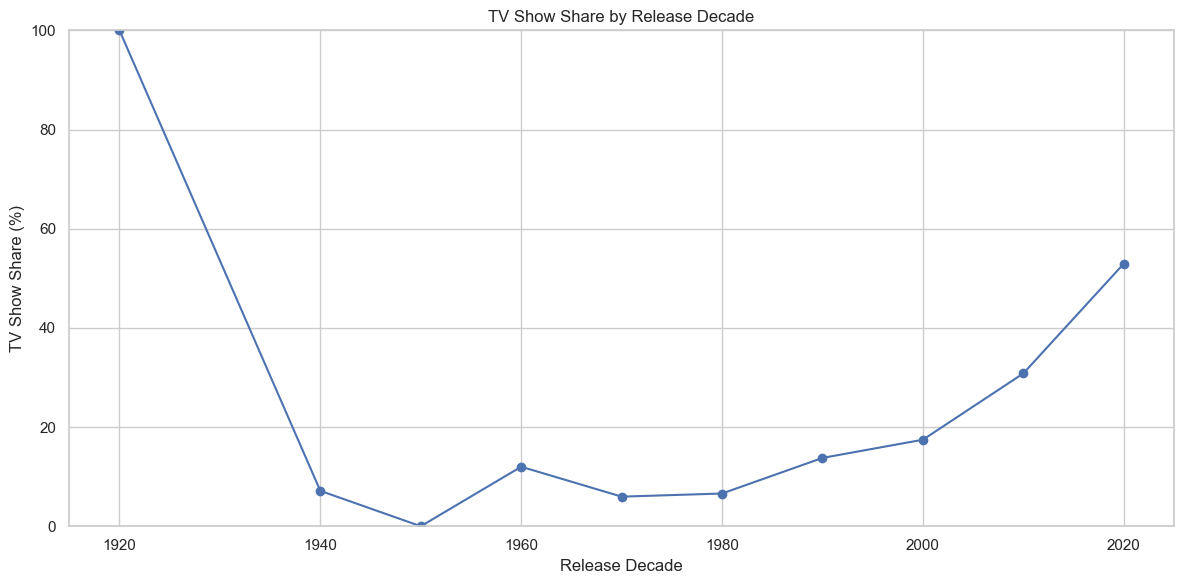

In [77]:
# Group release years into decades to reduce year-by-year noise.
df["release_decade"] = (df["release_year"] // 10) * 10

decade_type_counts = pd.crosstab(
    df["release_decade"],
    df["type"]
)

display(decade_type_counts)

decade_type_counts.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Movies and TV Shows by Release Decade")
plt.xlabel("Release Decade")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

tv_share_by_decade = (
    decade_type_counts["TV Show"]
    .div(decade_type_counts.sum(axis=1))
    .mul(100)
    .round(2)
)

plt.figure(figsize=(12, 6))
plt.plot(
    tv_share_by_decade.index,
    tv_share_by_decade.values,
    marker="o"
)

plt.title("TV Show Share by Release Decade")
plt.xlabel("Release Decade")
plt.ylabel("TV Show Share (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 4.3 Country × Content Type

Because some countries have very few titles, country-level percentages can become misleading. The full cross-tabulation is retained, but a **minimum of 10 title occurrences** is used when examining country-level composition. This threshold only reduces small-sample noise; it does not alter the dataset.

In [78]:
country_type = (
    df.assign(country_split=df["country"].str.split(", "))
      .explode("country_split")
)

country_type_counts = pd.crosstab(
    country_type["country_split"],
    country_type["type"]
)

print("Country × Content Type — All Countries")
display(country_type_counts)

country_occurrences = country_type["country_split"].value_counts()

valid_countries = country_occurrences[
    (country_occurrences >= 10) &
    (country_occurrences.index != "Unknown")
].index

country_type_filtered = country_type[
    country_type["country_split"].isin(valid_countries)
]

country_type_filtered_pct = pd.crosstab(
    country_type_filtered["country_split"],
    country_type_filtered["type"],
    normalize="index"
).mul(100).round(2)

print("Country × Content Type — Countries with at least 10 title occurrences")
display(country_type_filtered_pct)

Country × Content Type — All Countries


type,Movie,TV Show
country_split,,
Afghanistan,1,0
Albania,1,0
Algeria,2,0
Angola,1,0
Argentina,64,18
...,...,...
Vatican City,1,0
Venezuela,3,0
Vietnam,5,0


Country × Content Type — Countries with at least 10 title occurrences


type,Movie,TV Show
country_split,,
Argentina,78.05,21.95
Australia,58.33,41.67
Austria,90.91,9.09
Belgium,87.06,12.94
Brazil,67.05,32.95
Canada,69.42,30.58
Chile,80.77,19.23
China,69.39,30.61
Colombia,37.78,62.22


## 4.4 Genre × Rating

In [79]:
genre_rating = (
    df.assign(genre=df["listed_in"].str.split(", "))
      .explode("genre")
)

print("Number of genres/categories:", genre_rating["genre"].nunique())

genre_rating_pct = pd.crosstab(
    genre_rating["genre"],
    genre_rating["rating"],
    normalize="index"
).mul(100).round(2)

display(genre_rating_pct)

dominant_rating = genre_rating_pct.idxmax(axis=1)
dominant_percentage = genre_rating_pct.max(axis=1).round(2)

genre_rating_summary = pd.DataFrame({
    "Dominant Rating": dominant_rating,
    "Percentage": dominant_percentage
}).sort_values("Percentage", ascending=False)

print("Dominant rating associated with each genre/category:")
display(genre_rating_summary)

Number of genres/categories: 42


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
genre,,,,,,,,,,,,,,,
Action & Adventure,0.14,0.00,1.25,3.19,16.37,23.72,25.94,0.00,25.10,3.88,0.00,0.00,0.14,0.28,0.00
Anime Features,0.00,0.00,0.00,8.77,7.02,0.00,24.56,0.00,22.81,29.82,0.00,7.02,0.00,0.00,0.00
Anime Series,0.00,0.00,0.00,0.00,0.00,0.00,39.86,0.00,33.78,10.14,0.68,14.86,0.00,0.00,0.68
British TV Shows,0.00,0.00,0.86,0.00,0.00,0.00,18.53,6.47,41.38,23.28,7.33,2.16,0.00,0.00,0.00
Children & Family Movies,5.83,0.00,0.00,31.20,2.07,0.00,3.20,8.83,0.00,13.72,18.42,15.79,0.94,0.00,0.00
Classic & Cult TV,0.00,0.00,0.00,0.00,0.00,0.00,40.74,3.70,25.93,22.22,3.70,3.70,0.00,0.00,0.00
Classic Movies,6.80,0.00,2.91,12.62,8.74,26.21,20.39,0.97,10.68,10.68,0.00,0.00,0.00,0.00,0.00
Comedies,0.75,0.14,1.09,8.50,9.45,10.40,28.82,1.84,25.42,9.93,1.16,2.11,0.27,0.14,0.00
Crime TV Shows,0.00,0.00,0.23,0.00,0.00,0.00,24.36,0.23,73.54,0.94,0.00,0.70,0.00,0.00,0.00


Dominant rating associated with each genre/category:


,Dominant Rating,Percentage
genre,,
Stand-Up Comedy,TV-MA,85.41
TV Horror,TV-MA,76.81
Crime TV Shows,TV-MA,73.54
Spanish-Language TV Shows,TV-MA,71.43
Stand-Up Comedy & Talk Shows,TV-MA,69.23
TV Mysteries,TV-MA,67.78
TV Thrillers,TV-MA,64.00
LGBTQ Movies,TV-MA,58.89
TV Dramas,TV-MA,56.39


## 4.5 Release Decade × Rating

Year-by-year rating tables are too granular for interpretation. Release decades provide a more stable view of how rating composition changes over time. The full percentage table is calculated first; the plot then shows only the major rating categories.

Release Decade × Rating — Percentages


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
release_decade,,,,,,,,,,,,,,,
1920,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1940,0.00,0.00,0.00,0.00,0.00,0.00,50.00,0.00,7.14,42.86,0.00,0.00,0.00,0.00,0.00
1950,18.18,0.00,9.09,0.00,9.09,0.00,45.45,9.09,0.00,9.09,0.00,0.00,0.00,0.00,0.00
1960,8.00,0.00,0.00,0.00,8.00,16.00,28.00,4.00,12.00,24.00,0.00,0.00,0.00,0.00,0.00
1970,5.97,0.00,1.49,14.93,1.49,17.91,22.39,1.49,16.42,16.42,0.00,0.00,0.00,1.49,0.00
1980,1.89,0.00,2.83,8.49,6.60,13.21,40.57,0.00,12.26,12.26,0.00,1.89,0.00,0.00,0.00
1990,2.22,0.00,1.33,6.67,17.78,23.56,21.78,4.44,12.89,5.33,0.89,3.11,0.00,0.00,0.00
2000,1.79,0.00,0.82,8.65,15.80,15.80,27.47,0.69,14.15,10.30,0.96,3.16,0.00,0.41,0.00
2010,0.16,0.05,1.23,2.38,3.52,7.44,25.34,2.36,39.61,10.68,3.54,3.45,0.11,0.02,0.12


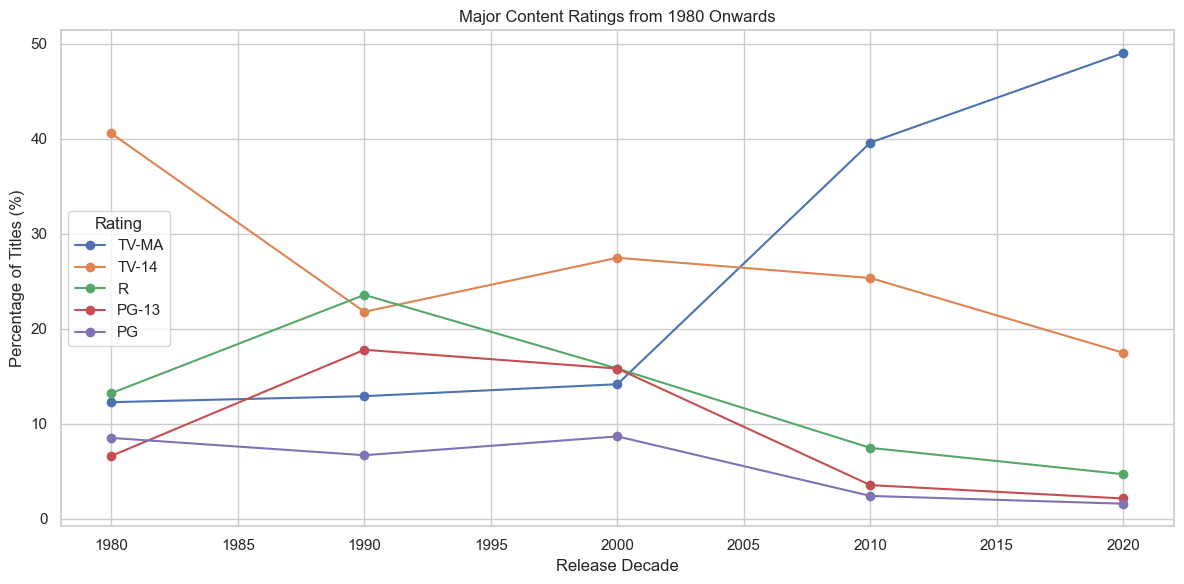

In [80]:
decade_rating_pct = pd.crosstab(
    df["release_decade"],
    df["rating"],
    normalize="index"
).mul(100).round(2)

print("Release Decade × Rating — Percentages")
display(decade_rating_pct)

major_ratings = ["TV-MA", "TV-14", "R", "PG-13", "PG"]

available_major_ratings = [
    rating for rating in major_ratings
    if rating in decade_rating_pct.columns
]

recent_decades = decade_rating_pct.loc[
    decade_rating_pct.index >= 1980,
    available_major_ratings
]

recent_decades.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Major Content Ratings from 1980 Onwards")
plt.xlabel("Release Decade")
plt.ylabel("Percentage of Titles (%)")
plt.legend(title="Rating")
plt.tight_layout()
plt.show()

# 5. Statistical Hypothesis Testing

The tests below evaluate selected relationships observed during EDA. Interpret p-values alongside effect size and test assumptions.

In [81]:
from scipy.stats import mannwhitneyu

# Separate release years by content type
movie_years = df.loc[
    df["type"] == "Movie", "release_year"
]

tv_years = df.loc[
    df["type"] == "TV Show", "release_year"
]

# Perform hypothesis test
statistic, p_value = mannwhitneyu(
    movie_years,
    tv_years,
    alternative="two-sided"
)

print("Movie median release year:", movie_years.median())
print("TV Show median release year:", tv_years.median())
print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: Release-year distributions differ.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Movie median release year: 2016.0
TV Show median release year: 2018.0
Mann-Whitney U statistic: 4666841.5
P-value: 7.507433995099372e-88
Reject H0: Release-year distributions differ.


In [82]:
from scipy.stats import chi2_contingency

# Create a contingency table
contingency_table = pd.crosstab(
    df["type"],
    df["rating"]
)

print("Contingency Table:")
display(contingency_table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

print(
    "Expected cell counts below 5:",
    (expected < 5).sum(),
    "out of",
    expected.size
)

alpha = 0.05

if p_value < alpha:
    print("Reject H0: Content type and rating are associated.")
else:
    print("Fail to reject H0: Insufficient evidence of an association.")

print("Minimum expected count:", expected.min())
print("Expected counts below 1:", (expected < 1).sum())

n = contingency_table.to_numpy().sum()
r, k = contingency_table.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, k - 1))
)

print("Cramér's V:", cramers_v)

Contingency Table:


rating,G,NC-17,NR,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7,TV-Y7-FV,UR,Unknown
type,,,,,,,,,,,,,,,
Movie,39,3,79,247,386,663,1272,111,1845,505,117,95,5,5,5
TV Show,0,0,5,0,0,2,659,83,1018,301,163,176,1,0,2


Chi-square statistic: 931.8954923986923
Degrees of freedom: 14
P-value: 6.306265095860963e-190
Expected cell counts below 5: 8 out of 30
Reject H0: Content type and rating are associated.
Minimum expected count: 0.9284705278027482
Expected counts below 1: 1
Cramér's V: 0.3459381974730075


# 6. Multivariate Exploratory Analysis

This visualization examines content type, release decade, and rating together. It is descriptive rather than causal.

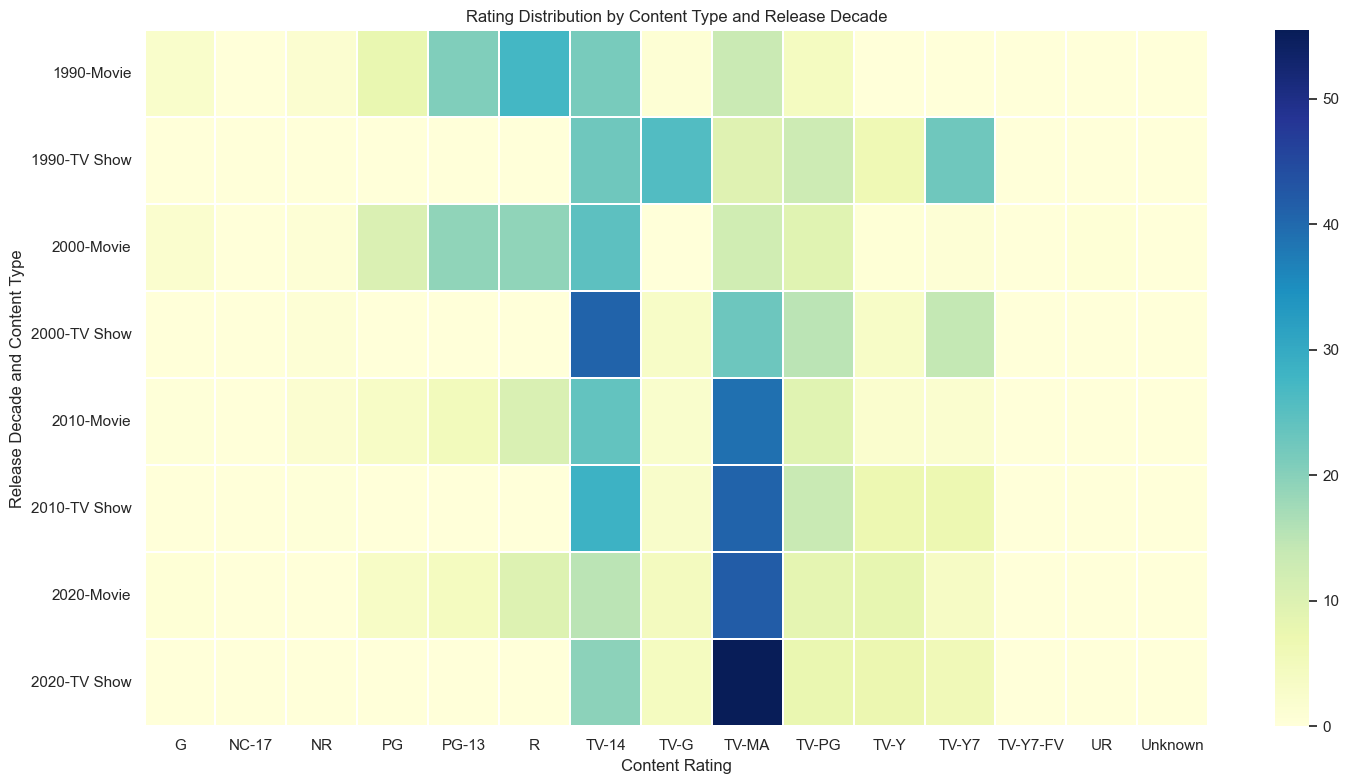

In [83]:
# Titles from 1990 onward with complete type, year, and rating values
rating_mv = df.dropna(subset=["type", "release_year", "rating"])
rating_mv = rating_mv[rating_mv["release_decade"].between(1990, 2020)].copy()

# Build a three-variable count table
type_rating_decade = pd.crosstab(
    [
        rating_mv["release_decade"],
        rating_mv["type"]
    ],
    rating_mv["rating"],
    normalize="index"
) * 100

plt.figure(figsize=(15, 8))

sns.heatmap(
    type_rating_decade,
    cmap="YlGnBu",
    annot=False,
    linewidths=0.3
)

plt.title(
    "Rating Distribution by Content Type and Release Decade"
)
plt.xlabel("Content Rating")
plt.ylabel("Release Decade and Content Type")
plt.tight_layout()
plt.show()

# 7. Feature Engineering and Representation

This section engineers several features for catalogue analysis and builds the numerical representation used for clustering.

- **Duration features:** Extracted to analyse movie runtimes and TV-show seasons.
- **Date-added features:** Extracted to analyse when titles were added to Netflix.
- **Genre features:** Multi-hot encoded to represent each title's categories.
- **Description features:** Converted into TF-IDF vectors to represent textual content.

The clustering feature matrix `X_features` combines only the genre indicators and description TF-IDF features. Duration and date-added features are engineered for exploratory analysis but are not included in this clustering matrix.

In [84]:
# FEATURE ENGINEERING: DURATION

# Extract numerical duration
df["duration_value"] = pd.to_numeric(
    df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

# Extract duration unit
df["duration_unit"] = (
    df["duration"]
    .str.extract(r"\d+\s*(.*)")[0]
    .str.strip()
)

# Separate movie runtime and TV Show seasons
df["movie_runtime_min"] = df["duration_value"].where(
    df["type"] == "Movie"
)

df["tv_seasons"] = df["duration_value"].where(
    df["type"] == "TV Show"
)

# Verify the transformation
display(
    df[[
        "type",
        "duration",
        "duration_value",
        "duration_unit",
        "movie_runtime_min",
        "tv_seasons"
    ]].head(10)
)

print("Unparsed durations:", df["duration_value"].isna().sum())
print("\nDuration units:")
display(df["duration_unit"].value_counts(dropna=False))

# FEATURE ENGINEERING: DATE ADDED

# Convert date_added to datetime
df["date_added"] = pd.to_datetime(
    df["date_added"].replace("Unknown", pd.NA),
    errors="coerce"
)

# Extract year and month
df["date_added_year"] = df["date_added"].dt.year
df["date_added_month"] = df["date_added"].dt.month

# Inspect the results
display(
    df[[
        "title",
        "date_added",
        "date_added_year",
        "date_added_month"
    ]].head(10)
)

print("Missing dates after conversion:", df["date_added"].isna().sum())

,type,duration,duration_value,duration_unit,movie_runtime_min,tv_seasons
0,TV Show,4 Seasons,4,Seasons,NaN,4.0
1,Movie,93 min,93,min,93.0,NaN
2,Movie,78 min,78,min,78.0,NaN
3,Movie,80 min,80,min,80.0,NaN
4,Movie,123 min,123,min,123.0,NaN
5,TV Show,1 Season,1,Season,NaN,1.0
6,Movie,95 min,95,min,95.0,NaN
7,Movie,119 min,119,min,119.0,NaN
8,Movie,118 min,118,min,118.0,NaN
9,Movie,143 min,143,min,143.0,NaN


Unparsed durations: 0

Duration units:


duration_unit
min        5377
Season     1608
Seasons     802
Name: count, dtype: int64

,title,date_added,date_added_year,date_added_month
0,3%,2020-08-14,2020.0,8.0
1,7:19,2016-12-23,2016.0,12.0
2,23:59,2018-12-20,2018.0,12.0
3,9,2017-11-16,2017.0,11.0
4,21,2020-01-01,2020.0,1.0
5,46,2017-07-01,2017.0,7.0
6,122,2020-06-01,2020.0,6.0
7,187,2019-11-01,2019.0,11.0
8,706,2019-04-01,2019.0,4.0
9,1920,2017-12-15,2017.0,12.0


Missing dates after conversion: 98


In [85]:
# FEATURE ENGINEERING: GENRE CATEGORIES

from sklearn.preprocessing import MultiLabelBinarizer

# Split each title's genre/category string into a list
genre_lists = (
    df["listed_in"]
    .fillna("Unknown")
    .str.split(", ")
)

# Convert multi-label categories into binary columns
mlb = MultiLabelBinarizer()
genre_encoded = mlb.fit_transform(genre_lists)

genre_df = pd.DataFrame(
    genre_encoded,
    columns=[f"genre_{g}" for g in mlb.classes_],
    index=df.index
)

print("Number of unique genres/categories:", len(mlb.classes_))
print("Genre feature matrix shape:", genre_df.shape)
display(genre_df.head())

# FEATURE ENGINEERING: DESCRIPTION TEXT USING TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=3000,
    ngram_range=(1, 2),
    min_df=2
)

description_tfidf = tfidf.fit_transform(
    df["description"].fillna("")
)

print("TF-IDF matrix shape:", description_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))
print("Sparse matrix:", description_tfidf.__class__.__name__)

# FEATURE ENGINEERING: COMBINE GENRE AND DESCRIPTION FEATURES

from scipy.sparse import hstack, csr_matrix

genre_sparse = csr_matrix(genre_df.values)

X_features = hstack(
    [description_tfidf, genre_sparse],
    format="csr"
)

print("Combined feature matrix shape:", X_features.shape)
print("Matrix type:", X_features.__class__.__name__)
print("Total titles:", X_features.shape[0])
print("Total features:", X_features.shape[1])
print("Non-zero values:", X_features.nnz)

Number of unique genres/categories: 42
Genre feature matrix shape: (7787, 42)


,genre_Action & Adventure,genre_Anime Features,genre_Anime Series,genre_British TV Shows,genre_Children & Family Movies,genre_Classic & Cult TV,genre_Classic Movies,genre_Comedies,genre_Crime TV Shows,genre_Cult Movies,genre_Documentaries,genre_Docuseries,genre_Dramas,genre_Faith & Spirituality,genre_Horror Movies,genre_Independent Movies,genre_International Movies,genre_International TV Shows,genre_Kids' TV,genre_Korean TV Shows,genre_LGBTQ Movies,genre_Movies,genre_Music & Musicals,genre_Reality TV,genre_Romantic Movies,genre_Romantic TV Shows,genre_Sci-Fi & Fantasy,genre_Science & Nature TV,genre_Spanish-Language TV Shows,genre_Sports Movies,genre_Stand-Up Comedy,genre_Stand-Up Comedy & Talk Shows,genre_TV Action & Adventure,genre_TV Comedies,genre_TV Dramas,genre_TV Horror,genre_TV Mysteries,genre_TV Sci-Fi & Fantasy,genre_TV Shows,genre_TV Thrillers,genre_Teen TV Shows,genre_Thrillers
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


TF-IDF matrix shape: (7787, 3000)
Vocabulary size: 3000
Sparse matrix: csr_matrix
Combined feature matrix shape: (7787, 3042)
Matrix type: csr_matrix
Total titles: 7787
Total features: 3042
Non-zero values: 97452


# 8. Modelling Setup

This project uses unsupervised learning because the objective is to discover groups of similar Netflix titles rather than predict a predefined target label.

Genre indicators and TF-IDF description vectors are combined into the sparse matrix `X_features`. MiniBatch K-Means is fitted directly on this matrix. Agglomerative Clustering and the final standardised comparison use a 50-component Truncated SVD reduction of the same matrix.

One fixed sample of 1,500 titles is created for computationally expensive clustering metrics and reused by every later step. Model fitting may still use the full dataset.

In [86]:
# Fixed evaluation sample shared by all clustering experiments
rng = np.random.RandomState(42)
sample_size = min(1500, X_features.shape[0])
sample_indices = rng.choice(
    X_features.shape[0],
    size=sample_size,
    replace=False
)
X_sample = X_features[sample_indices]

print("Evaluation sample size:", sample_size)

Evaluation sample size: 1500


# 9. Model 1 — MiniBatch K-Means

The elbow curve and sampled silhouette scores guide the choice of k. A feature-set check confirms that genre indicators add information beyond the descriptions alone, and a seed-stability check precedes the final fit and evaluation.

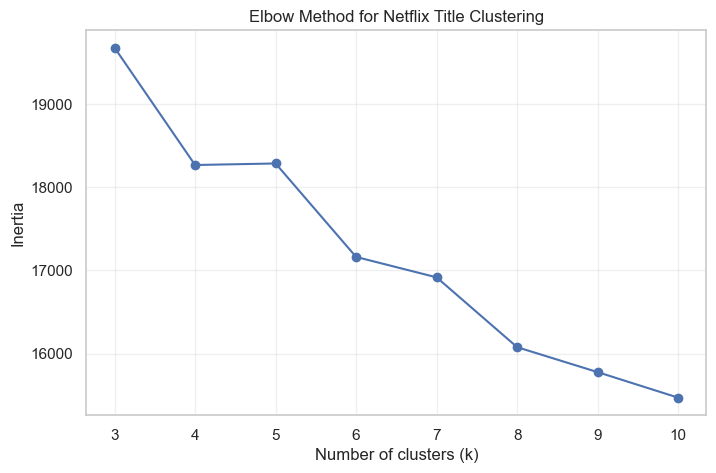

,k,inertia
0,3,19675.439968
1,4,18265.899028
2,5,18284.308354
3,6,17161.510163
4,7,16916.210968
5,8,16077.468103
6,9,15777.675787
7,10,15470.898508


,k,silhouette_score
0,4,0.180683
1,6,0.177544
2,8,0.189112


In [87]:
# CLUSTERING: FIND A REASONABLE NUMBER OF CLUSTERS

from sklearn.cluster import MiniBatchKMeans

k_values = [3, 4, 5, 6, 7, 8, 9, 10]
inertias = []

for k in k_values:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=256,
        n_init=3
    )
    model.fit(X_features)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Netflix Title Clustering")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.show()

display(
    pd.DataFrame({
        "k": k_values,
        "inertia": inertias
    })
)

# CLUSTERING EVALUATION: SILHOUETTE SCORE

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score

X_sample = X_features[sample_indices]

silhouette_results = []

for k in [4, 6, 8]:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=42,
        batch_size=256,
        n_init=5,
        max_iter=200
    )

    model.fit(X_features)
    sample_labels = model.labels_[sample_indices]

    score = silhouette_score(
        X_sample,
        sample_labels,
        metric="cosine"
    )

    silhouette_results.append({
        "k": k,
        "silhouette_score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)
display(silhouette_df)

In [88]:
# MODEL COMPARISON: DESCRIPTION TF-IDF ONLY VS COMBINED FEATURES

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import silhouette_score
from scipy.sparse import csr_matrix

comparison_results = []

# Reuse the same sample indices for a fair comparison
feature_sets = {
    "Description TF-IDF only": description_tfidf,
    "Description + genres": X_features
}

for feature_name, X in feature_sets.items():
    model = MiniBatchKMeans(
        n_clusters=8,
        random_state=42,
        batch_size=256,
        n_init=5,
        max_iter=200
    )

    model.fit(X)

    score = silhouette_score(
        X[sample_indices],
        model.labels_[sample_indices],
        metric="cosine"
    )

    comparison_results.append({
        "features": feature_name,
        "silhouette_score": score
    })

display(pd.DataFrame(comparison_results))

,features,silhouette_score
0,Description TF-IDF only,0.005002
1,Description + genres,0.189112


In [89]:
# STABILITY CHECK WITH MORE INITIALIZATIONS

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import adjusted_rand_score

stable_model_a = MiniBatchKMeans(
    n_clusters=8,
    random_state=42,
    batch_size=256,
    n_init=20,
    max_iter=300
)

stable_model_b = MiniBatchKMeans(
    n_clusters=8,
    random_state=21,
    batch_size=256,
    n_init=20,
    max_iter=300
)

stable_labels_a = stable_model_a.fit_predict(X_features)
stable_labels_b = stable_model_b.fit_predict(X_features)

stable_ari = adjusted_rand_score(
    stable_labels_a,
    stable_labels_b
)

print("ARI with n_init=20:", round(stable_ari, 4))

# EVALUATE THE IMPROVED K=8 MODEL

df["cluster"] = stable_labels_a

cluster_sizes = (
    df["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .to_frame("number_of_titles")
)

display(cluster_sizes)

print("Total assigned:", df["cluster"].notna().sum())
print("Number of clusters:", df["cluster"].nunique())

# FINAL CANDIDATE EVALUATION

from sklearn.metrics import silhouette_score

improved_silhouette = silhouette_score(
    X_features[sample_indices],
    stable_labels_a[sample_indices],
    metric="cosine"
)

print(
    "Silhouette score (improved K=8 model):",
    round(improved_silhouette, 6)
)

ARI with n_init=20: 0.6618


,number_of_titles
cluster,
0,1066
1,598
2,73
3,1795
4,1382
5,1941
6,329
7,603


Total assigned: 7787
Number of clusters: 8
Silhouette score (improved K=8 model): 0.186212


# 10. Model 2 — Agglomerative Clustering

Truncated SVD reduces the sparse combined genre-and-description matrix to 50 components. Ward linkage is then applied to this reduced representation. Its Euclidean silhouette score should not be directly ranked against the cosine scores computed on the original sparse matrix in Section 9.

In [90]:
from sklearn.decomposition import TruncatedSVD

# Apply Truncated SVD to the COMBINED feature matrix
svd = TruncatedSVD(
    n_components=50,
    random_state=42,
    n_iter=7
)

X_reduced = svd.fit_transform(X_features)

print("Original shape:", X_features.shape)
print("Reduced shape:", X_reduced.shape)
print(
    "Explained variance ratio:",
    round(svd.explained_variance_ratio_.sum(), 4)
)

# AGGLOMERATIVE CLUSTERING (WARD LINKAGE)

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

agglomerative_model = AgglomerativeClustering(
    n_clusters=8,
    linkage="ward"
)

agglomerative_labels = agglomerative_model.fit_predict(X_reduced)

print("Number of clusters:", len(set(agglomerative_labels)))

print("\nCluster sizes:")
display(
    pd.Series(agglomerative_labels, name="cluster")
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .to_frame("number_of_titles")
)

# Evaluate on the same sampled rows
agglomerative_silhouette = silhouette_score(
    X_reduced[sample_indices],
    agglomerative_labels[sample_indices],
    metric="euclidean"
)

print(
    "\nAgglomerative silhouette score:",
    round(agglomerative_silhouette, 6)
)

Original shape: (7787, 3042)
Reduced shape: (7787, 50)
Explained variance ratio: 0.669
Number of clusters: 8

Cluster sizes:


,number_of_titles
cluster,
0,1411
1,1068
2,1636
3,586
4,953
5,1378
6,389
7,366



Agglomerative silhouette score: 0.165283


# 11. Final Model Comparison

This section compares MiniBatch K-Means and Agglomerative Clustering on the same evaluation sample and the same normalised 50-component SVD representation. This standardised setup is distinct from the model-specific experiments above, which use different representations or metrics.

1. Verify and normalise the evaluation matrix.
2. Fit both models on the shared sample and compute internal metrics. Silhouette and Calinski–Harabasz are higher-is-better; Davies–Bouldin is lower-is-better.
3. Plot each metric separately to keep its scale and direction clear.
4. Inspect cluster contents. Genre counts may exceed cluster size because titles can have multiple categories.

In [91]:
# Verify that the reduced matrix and the fixed evaluation sample align
print("Reduced feature matrix:", X_reduced.shape)
print("Evaluation sample size:", len(sample_indices))
print("Sampled feature matrix:", X_reduced[sample_indices].shape)

assert X_reduced.shape[0] == len(df), \
    "X_reduced and df have different row counts."

assert X_reduced.shape[1] == 50, \
    "Expected 50 SVD components."

print("\nEvaluation data checks passed.")

# Use the same 1,500 titles for every model and L2-normalise each title's vector
from sklearn.preprocessing import normalize

X_eval = X_reduced[sample_indices]
X_eval_norm = normalize(X_eval, norm="l2")

print("Evaluation matrix shape:", X_eval_norm.shape)
print("First 5 vector norms:",
      (X_eval_norm[:5] ** 2).sum(axis=1) ** 0.5)

Reduced feature matrix: (7787, 50)
Evaluation sample size: 1500
Sampled feature matrix: (1500, 50)

Evaluation data checks passed.
Evaluation matrix shape: (1500, 50)
First 5 vector norms: [1. 1. 1. 1. 1.]


In [92]:
from sklearn.cluster import MiniBatchKMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Fit both models on the shared normalised evaluation sample
labels_mbk = MiniBatchKMeans(
    n_clusters=8,
    random_state=42,
    batch_size=256,
    n_init=10,
    max_iter=300
).fit_predict(X_eval_norm)

labels_agg = AgglomerativeClustering(
    n_clusters=8,
    linkage="ward"
).fit_predict(X_eval_norm)

label_sets = {
    "MiniBatch K-Means": labels_mbk,
    "Agglomerative": labels_agg
}

for name, labels in label_sets.items():
    print(f"{name}: {len(set(labels))} clusters")

# Internal clustering metrics on the shared sample
def evaluate_clustering(X, labels):
    return {
        "Silhouette Score": silhouette_score(X, labels, metric="euclidean"),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels),
        "Calinski-Harabasz Index": calinski_harabasz_score(X, labels)
    }

comparison_df = pd.DataFrame(
    {name: evaluate_clustering(X_eval_norm, labels)
     for name, labels in label_sets.items()}
).T

comparison_df.insert(
    0, "Clusters",
    [len(set(labels)) for labels in label_sets.values()]
)

display(comparison_df.round(4))

MiniBatch K-Means: 8 clusters
Agglomerative: 8 clusters


,Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
MiniBatch K-Means,8,0.2660,1.6548,168.3906
Agglomerative,8,0.2315,1.7912,145.9998


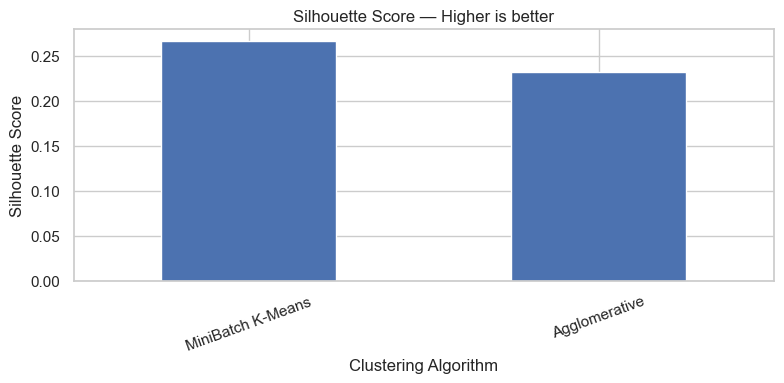

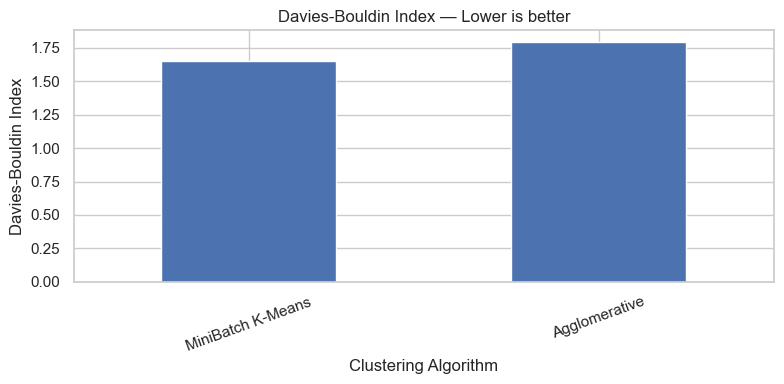

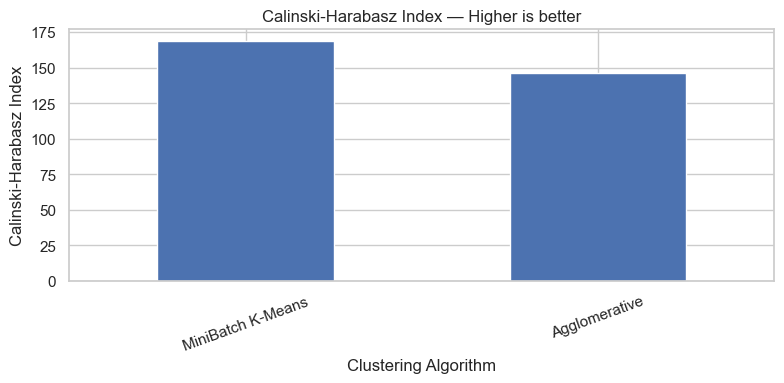

In [93]:
import matplotlib.pyplot as plt

metrics_to_plot = [
    ("Silhouette Score", "Higher is better"),
    ("Davies-Bouldin Index", "Lower is better"),
    ("Calinski-Harabasz Index", "Higher is better")
]

for metric, direction in metrics_to_plot:
    ax = comparison_df[metric].plot(
        kind="bar",
        figsize=(8, 4),
        title=f"{metric} — {direction}"
    )

    ax.set_ylabel(metric)
    ax.set_xlabel("Clustering Algorithm")
    ax.tick_params(axis="x", rotation=20)

    plt.tight_layout()
    plt.show()

In [94]:
# Cluster contents on the shared evaluation sample
eval_titles = df.iloc[sample_indices][
    ["title", "type", "listed_in"]
].copy().reset_index(drop=True)

for model_name, labels in label_sets.items():
    print(f"\n{'=' * 60}")
    print(model_name)
    print("=" * 60)

    temp = eval_titles.copy()
    temp["cluster"] = labels

    for cluster_id in temp["cluster"].value_counts().index:
        group = temp[temp["cluster"] == cluster_id]

        genres = (
            group["listed_in"]
            .dropna()
            .str.split(", ")
            .explode()
            .value_counts()
        )

        print(
            f"\nCluster {cluster_id}: "
            f"{len(group)} titles"
        )
        print("Top genres:", genres.head(5).to_dict())
        print(
            "Representative titles:",
            group["title"].head(3).tolist()
        )


MiniBatch K-Means

Cluster 3: 356 titles
Top genres: {'International TV Shows': 228, 'TV Dramas': 123, 'Crime TV Shows': 73, 'Romantic TV Shows': 60, 'Docuseries': 59}
Representative titles: ['Lady, la vendedora de rosas', 'Goodbye My Wife', 'Last Tango in Halifax']

Cluster 1: 321 titles
Top genres: {'International Movies': 303, 'Dramas': 191, 'Comedies': 155, 'Romantic Movies': 92, 'Thrillers': 36}
Representative titles: ['Ravenous', 'Tere Naal Love Ho Gaya', 'Kaal']

Cluster 7: 241 titles
Top genres: {'Dramas': 181, 'Independent Movies': 136, 'Thrillers': 51, 'International Movies': 49, 'Comedies': 44}
Representative titles: ['Our Idiot Brother', 'Listen', 'Trespass Against Us']

Cluster 2: 154 titles
Top genres: {'Documentaries': 154, 'International Movies': 53, 'Music & Musicals': 22, 'Sports Movies': 18, 'LGBTQ Movies': 7}
Representative titles: ['Unchained: The Untold Story of Freestyle Motocross', '3 Seconds Divorce', 'One Take']

Cluster 6: 138 titles
Top genres: {'Action & A

# 12. Conclusion

This project analysed the Netflix catalogue using exploratory data analysis, statistical hypothesis testing, feature engineering, and two unsupervised clustering algorithms. All summaries and takeaways are collected here.

## Exploratory findings

1. **Release-year differences:** The median release year was 2016 for movies and 2018 for TV shows. The Mann–Whitney U test returned a p-value of approximately \(7.51 \times 10^{-88}\), indicating a statistically significant difference between their release-year distributions.

2. **Association between content type and rating:** The chi-square test returned a statistic of 931.90 with 14 degrees of freedom and a p-value of approximately \(6.31 \times 10^{-190}\). Cramér's V was 0.346, indicating an association between content type and rating. Some expected cell counts were small, so the chi-square assumptions should be reviewed before drawing a firm inferential conclusion.

3. **Catalogue diversity:** The dataset contains multiple genres and country labels, demonstrating diversity in the catalogue. Since a title may belong to several genres or countries, these categories are not mutually exclusive.

These findings describe patterns in the available catalogue; they do not establish causal relationships or explain individual viewing preferences.

## Clustering findings

**Feature representation.** Genre indicators and TF-IDF description vectors were combined and reduced to 50 components with Truncated SVD for Agglomerative Clustering and the standardised comparison. Adding genre indicators raised the sampled cosine silhouette score from 0.0050 (descriptions only) to 0.1891.

**Model 1 — MiniBatch K-Means.** k = 8 gave the highest sampled silhouette score among the tested values (0.1891, compared with 0.1807 for k = 4 and 0.1775 for k = 6). With 20 initialisations, two different random seeds produced partitions with an Adjusted Rand Index of 0.6618, so the grouping is reasonably but not perfectly stable. The final full-data model scored 0.1862 on the evaluation sample.

**Model 2 — Agglomerative Clustering.** Ward linkage on the 50-component representation produced eight clusters. Its Euclidean silhouette score on the evaluation sample (0.1653, unnormalised SVD space) is not directly comparable with the cosine scores computed for MiniBatch K-Means on the sparse matrix.

**Standardised comparison.** On the common sample of 1,500 titles (50 normalised SVD components), MiniBatch K-Means achieved a silhouette score of 0.2660, a Davies–Bouldin index of 1.6548, and a Calinski–Harabasz index of 168.3906. Agglomerative Clustering achieved 0.2315, 1.7912, and 145.9998 respectively. MiniBatch K-Means was therefore better on all three metrics.

**Cluster contents.** MiniBatch K-Means clusters included recognisable groups such as documentaries, international TV, action and adventure, children's content, and stand-up comedy. Agglomerative Clustering also identified interpretable groups, including stand-up comedy, children's content, documentaries, and international TV, but its internal evaluation scores were lower in this experiment.

## Overall interpretation

MiniBatch K-Means is the preferred model for this experiment because it combines the stronger internal metrics with reasonably interpretable cluster contents. The modest silhouette scores and the presence of mixed clusters nevertheless indicate that the catalogue is not perfectly separated in the chosen feature space. The results show that metadata and textual descriptions can be used to explore similarities and organise Netflix titles into content-based groups, but the internal metrics do not establish that the groups are objectively correct.

## Scope and limitations

The dataset contains no individual user-interaction histories, so this study does not evaluate personalised recommendations or predict viewing behaviour. The project fulfils its objective of analysing catalogue patterns and comparing content-based clustering techniques within the limitations of the available data.